# Task 2: Yelp Polarity sentiment classification

Three models with embeddings learned from scratch (no pretrained embeddings or language models):
a mean-embedding **baseline**, a **BiLSTM** and a **TextCNN**.

**How to run (only this one file is needed):**
1. In Colab: File → Upload notebook → choose this file.
2. Runtime → Change runtime type → choose a **GPU**.
3. Runtime → Run all.

Everything is saved in Google Drive under `MyDrive/DATA266_task2/`. If Colab disconnects, just Run all again:
finished models are not retrained.
At the end, a `task2_results.zip` downloads. Unzip it into the repo root to add the results to GitHub.

## 1. GPU

In [1]:
!nvidia-smi

Fri Oct  2 03:15:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P0             47W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 2. Working folder in Google Drive

In [2]:
import os
from google.colab import drive
drive.mount('/content/drive')

WORK = "/content/drive/MyDrive/DATA266_task2"  # same folder layout as the GitHub repo
os.makedirs(f"{WORK}/task2_sentiment/scripts", exist_ok=True)
os.makedirs(f"{WORK}/task2_sentiment/kruthika/src", exist_ok=True)
%cd "{WORK}"

Mounted at /content/drive
/content/drive/MyDrive/DATA266_task2


## 3. Install packages
PyTorch, scikit-learn, SciPy, pandas and Matplotlib are already on Colab.

In [3]:
!pip install -q pyyaml datasets nltk

## 4. Code
Each cell writes one file of the repo (identical to the GitHub version).

### Dataset download
`task2_sentiment/scripts/download_yelp_polarity.py`

In [4]:
%%writefile task2_sentiment/scripts/download_yelp_polarity.py
"""Download the Yelp Polarity dataset from Hugging Face into task2_sentiment/data/yelp_polarity/.

Official splits: train 560,000 reviews, test 38,000 reviews (both perfectly balanced).
Labels: 0 = negative (1-2 stars), 1 = positive (3-4 stars), as defined by the dataset authors.

Usage (from the repo root):
    python task2_sentiment/scripts/download_yelp_polarity.py
"""
from pathlib import Path

from datasets import load_dataset

# Pinned dataset version, so every team member gets exactly the same data.
REVISION = "bbf1c97a1f0cf005e5aded43839fd814654a1557"

# find task2_sentiment folder
current_file = Path(__file__).resolve()
scripts_folder = current_file.parent
task2 = scripts_folder.parent
# find data folder in task2_sentiment
data_folder = task2 / "data"
# find yelp_polarity folder in task2_sentiment/data
dataset_folder = data_folder / "yelp_polarity"


def download_yelp_polarity():
    """Download and save the dataset if it is not there yet; return its folder."""
    data_folder.mkdir(parents=True, exist_ok=True)
    if dataset_folder.is_dir():
        print("Dataset already exists.")
    else:
        dataset = load_dataset("fancyzhx/yelp_polarity", revision=REVISION)
        dataset.save_to_disk(dataset_folder)
        print("Download complete")
        for split, part in dataset.items():
            print(f"  {split}: {len(part):,} reviews")
    return dataset_folder


if __name__ == "__main__":
    download_yelp_polarity()

Writing task2_sentiment/scripts/download_yelp_polarity.py


### Config: preprocessing, models, training settings
`task2_sentiment/kruthika/src/config.yaml`

In [5]:
%%writefile task2_sentiment/kruthika/src/config.yaml
# Task 2: Yelp Polarity sentiment classification. All paths are relative to the repo root.

seed: 42
device: auto                 # cuda > mps > cpu

data:
  data_dir: task2_sentiment/data/yelp_polarity   # saved by task2_sentiment/scripts/download_yelp_polarity.py
  val_fraction: 0.1          # of the official train split (stratified); the official test split is the test set
  stemming: true             # Porter stemming after stopword removal (negations are kept)
  min_freq: 5                # a word must appear 5+ times in training to get its own embedding
  max_vocab: 50000
  max_len: 256               # tokens per review after preprocessing (~98% of reviews fit)

train:
  batch_size: 256
  epochs: 5                  # maximum; early stopping on validation loss
  patience: 2                # stop after 2 epochs without validation-loss improvement
  grad_clip: 1.0

eval:
  bootstrap: 1000            # resamples for 95% confidence intervals
  ece_bins: 15

# Embeddings are learned from scratch in every model (no pretrained vectors).
models:
  baseline_mean_embedding:   # bag of words: average embedding -> linear
    type: mean_embedding
    embed_dim: 128
    dropout: 0.3
    lr: 2.0e-3
  exp1_bilstm:               # word order + context: 1-layer bidirectional LSTM, max+mean pooling
    type: bilstm
    embed_dim: 128
    hidden: 128
    layers: 1
    dropout: 0.3
    lr: 1.0e-3
  exp2_textcnn:              # local phrases: convolutions over 3/4/5 words, max-over-time pooling
    type: textcnn
    embed_dim: 128
    filters: 128
    kernel_sizes: [3, 4, 5]
    dropout: 0.5
    lr: 1.0e-3

Writing task2_sentiment/kruthika/src/config.yaml


### Task 2.1: data analysis and preprocessing
`task2_sentiment/kruthika/src/data.py`

In [6]:
%%writefile task2_sentiment/kruthika/src/data.py
"""Task 2.1 - data analysis and preprocessing for Yelp Polarity.

Pipeline: raw review -> clean (lowercase, fix escaped newlines, expand "n't", drop
punctuation/digits) -> tokenise -> remove stopwords (keeping negations) -> Porter stem
-> integer ids from a vocabulary built on the training split -> fixed-length padded arrays.
"""
import re
from collections import Counter
from functools import lru_cache

import numpy as np

PAD, UNK = 0, 1

# NLTK's English stopword list contains negations; removing them would turn
# "not good" into "good" and flip the sentiment, so they are kept.
NEGATIONS = {"no", "not", "nor", "never", "none", "nothing", "nobody", "nowhere", "neither", "cannot"}
CONTRAST = {"but", "however", "although", "though", "yet"}


def load_stopwords():
    import nltk
    try:
        from nltk.corpus import stopwords
        words = stopwords.words("english")
    except LookupError:
        nltk.download("stopwords", quiet=True)
        from nltk.corpus import stopwords
        words = stopwords.words("english")
    # Contraction fragments ("didn", "wasn", ...) are covered by expanding n't -> not.
    return set(words) - NEGATIONS


_stemmer = None


@lru_cache(maxsize=None)
def stem(word):
    """Porter stem, cached: the vocabulary is small compared to the token count."""
    global _stemmer
    if _stemmer is None:
        from nltk.stem import PorterStemmer
        _stemmer = PorterStemmer()
    return _stemmer.stem(word)


_ESCAPED = re.compile(r'\\n|\\"|\\t')     # literal "\n" etc. stored as text in this dataset
_ENTITY = re.compile(r"&[a-z]+;|&#\d+;")    # HTML entities such as &amp;
_NEGATION = re.compile(r"n['’]t\b")          # didn't -> did not
_NON_ALPHA = re.compile(r"[^a-z\s]")        # punctuation, digits, special characters


def clean_text(text):
    text = text.lower()
    text = _ESCAPED.sub(" ", text)
    text = _ENTITY.sub(" ", text)
    text = text.replace("can't", "can not").replace("won't", "will not")
    text = _NEGATION.sub(" not", text)
    text = text.replace("'", "")   # don't split remaining contractions: "i'm" -> "im"
    return _NON_ALPHA.sub(" ", text)


def preprocess(text, stopwords, use_stemming=True):
    """Raw review -> list of tokens."""
    tokens = [t for t in clean_text(text).split() if (t not in stopwords and len(t) > 1) or t in NEGATIONS]
    return [stem(t) for t in tokens] if use_stemming else tokens


def build_vocab(token_lists, min_freq, max_size):
    """Words seen at least min_freq times in training, most frequent first; 0 = <pad>, 1 = <unk>."""
    counts = Counter(t for toks in token_lists for t in toks)
    words = [w for w, c in counts.most_common(max_size) if c >= min_freq]
    vocab = {"<pad>": PAD, "<unk>": UNK}
    for w in words:
        vocab[w] = len(vocab)
    return vocab


def encode(token_lists, vocab, max_len):
    """Token lists -> (ids [N, max_len] int32 padded with 0, lengths [N]).
    Reviews longer than max_len are truncated; empty reviews become a single <unk>."""
    ids = np.zeros((len(token_lists), max_len), dtype=np.int32)
    lengths = np.zeros(len(token_lists), dtype=np.int32)
    for i, toks in enumerate(token_lists):
        seq = [vocab.get(t, UNK) for t in toks[:max_len]] or [UNK]
        ids[i, :len(seq)] = seq
        lengths[i] = len(seq)
    return ids, lengths


def stratified_split(labels, val_fraction, seed):
    """Indices for train/validation with the same class ratio in both."""
    rng = np.random.default_rng(seed)
    train_idx, val_idx = [], []
    for c in np.unique(labels):
        idx = rng.permutation(np.flatnonzero(labels == c))
        n_val = int(round(len(idx) * val_fraction))
        val_idx.append(idx[:n_val])
        train_idx.append(idx[n_val:])
    return np.sort(np.concatenate(train_idx)), np.sort(np.concatenate(val_idx))


def data_quality(train_texts, test_texts):
    """Counts of missing / malformed / duplicated entries (brief 2.1.2)."""
    train_set = set(train_texts)
    return {
        "train_missing_or_empty": sum(1 for t in train_texts if not isinstance(t, str) or not t.strip()),
        "test_missing_or_empty": sum(1 for t in test_texts if not isinstance(t, str) or not t.strip()),
        "train_duplicate_texts": len(train_texts) - len(train_set),
        "test_texts_also_in_train": sum(1 for t in set(test_texts) if t in train_set),
        "train_with_escaped_newlines": sum(1 for t in train_texts if "\\n" in t),
        "train_with_html_entities": sum(1 for t in train_texts if _ENTITY.search(t.lower())),
    }


def slices(raw_texts):
    """Data slices for robustness analysis: review length, negation, contrast words."""
    words = [t.lower().split() for t in raw_texts]
    n_words = np.array([len(w) for w in words])
    length = np.where(n_words <= 50, "short (<=50 words)",
                      np.where(n_words <= 200, "medium (51-200)", "long (>200)"))
    has_neg = np.array([any(x.strip(".,!?\"'") in NEGATIONS or "n't" in x for x in w) for w in words])
    has_con = np.array([any(x.strip(".,!?\"'") in CONTRAST for x in w) for w in words])
    return {
        "length": length,
        "negation": np.where(has_neg, "has negation", "no negation"),
        "contrast": np.where(has_con, "has contrast word", "no contrast word"),
    }

Writing task2_sentiment/kruthika/src/data.py


### Task 2.2: the three models
`task2_sentiment/kruthika/src/models.py`

In [7]:
%%writefile task2_sentiment/kruthika/src/models.py
"""Task 2.2 - three sentiment classifiers, all with word embeddings learned from scratch.

Each model maps (ids [B, T], lengths [B]) -> one logit per review; sigmoid(logit) = P(positive).
"""
import torch
import torch.nn as nn


def _mask(ids):
    return (ids != 0).unsqueeze(-1)  # (B, T, 1): True for real tokens, False for padding


class MeanEmbedding(nn.Module):
    """Baseline: average of word embeddings -> linear layer (fastText-style bag of words).
    Ignores word order entirely; fast and a strong reference point."""

    def __init__(self, vocab_size, embed_dim, dropout, **_):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(embed_dim, 1)

    def forward(self, ids, lengths):
        m = _mask(ids)
        mean = (self.emb(ids) * m).sum(1) / m.sum(1).clamp(min=1)
        return self.fc(self.drop(mean)).squeeze(-1)


class BiLSTM(nn.Module):
    """Experimental 1: bidirectional LSTM reads the review left-to-right and right-to-left,
    so each position sees its context (e.g. "not ... good"). Max- and mean-pooling over time
    combine the strongest signals with the overall tone."""

    def __init__(self, vocab_size, embed_dim, hidden, layers, dropout, **_):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(embed_dim, hidden, num_layers=layers, batch_first=True, bidirectional=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.fc = nn.Linear(4 * hidden, 1)  # [max-pool ; mean-pool] of 2*hidden each

    def forward(self, ids, lengths):
        x = self.drop(self.emb(ids))
        # Packing skips the padding, so the backward direction starts at the real last word.
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=ids.size(1))
        m = _mask(ids)
        max_pool = out.masked_fill(~m, float("-inf")).max(1).values
        mean_pool = (out * m).sum(1) / m.sum(1).clamp(min=1)
        return self.fc(self.drop(torch.cat([max_pool, mean_pool], dim=1))).squeeze(-1)


class TextCNN(nn.Module):
    """Experimental 2: 1-D convolutions with 3-, 4- and 5-word filters detect local phrases
    ("not worth it", "highly recommend"); max-over-time keeps each filter's strongest match."""

    def __init__(self, vocab_size, embed_dim, filters, kernel_sizes, dropout, **_):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(embed_dim, filters, k) for k in kernel_sizes])
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(filters * len(kernel_sizes), 1)
        self.min_len = max(kernel_sizes)

    def forward(self, ids, lengths):
        if ids.size(1) < self.min_len:  # sequences must be at least as long as the widest filter
            ids = nn.functional.pad(ids, (0, self.min_len - ids.size(1)))
        x = self.emb(ids).transpose(1, 2)  # (B, embed_dim, T) for Conv1d
        pooled = [torch.relu(conv(x)).max(dim=2).values for conv in self.convs]
        return self.fc(self.drop(torch.cat(pooled, dim=1))).squeeze(-1)


MODELS = {"mean_embedding": MeanEmbedding, "bilstm": BiLSTM, "textcnn": TextCNN}


def build_model(cfg, vocab_size):
    return MODELS[cfg["type"]](vocab_size=vocab_size, **cfg)

Writing task2_sentiment/kruthika/src/models.py


### Metrics and plots
`task2_sentiment/kruthika/src/evaluate.py`

In [8]:
%%writefile task2_sentiment/kruthika/src/evaluate.py
"""Task 2 evaluation metrics and plots (binary classification, positive class = 1).

All metrics take y (true labels 0/1) and p (predicted probability of class 1);
the predicted label is p >= 0.5.
"""
import numpy as np
from scipy.stats import binomtest, chi2
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, matthews_corrcoef, precision_recall_fscore_support, roc_auc_score)


def expected_calibration_error(y, p, n_bins=15):
    """ECE: split predictions into confidence bins; weighted mean |accuracy - confidence|.
    Confidence = probability of the predicted class."""
    pred = (p >= 0.5).astype(int)
    conf = np.where(pred == 1, p, 1 - p)
    correct = (pred == y).astype(float)
    edges = np.linspace(0.5, 1.0, n_bins + 1)
    ece, bins = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        inb = (conf > lo) & (conf <= hi) if lo > 0.5 else (conf >= lo) & (conf <= hi)
        if inb.any():
            acc, cf = correct[inb].mean(), conf[inb].mean()
            ece += inb.mean() * abs(acc - cf)
            bins.append((lo, hi, int(inb.sum()), acc, cf))
    return ece, bins


def classification_metrics(y, p, ece_bins=15):
    pred = (p >= 0.5).astype(int)
    out = {"accuracy": accuracy_score(y, pred)}
    for avg in ("macro", "micro", "weighted"):
        pr, rc, f1, _ = precision_recall_fscore_support(y, pred, average=avg, zero_division=0)
        out[f"precision_{avg}"], out[f"recall_{avg}"], out[f"f1_{avg}"] = pr, rc, f1
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    out.update({"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)})
    out["roc_auc"] = roc_auc_score(y, p)
    out["pr_auc"] = average_precision_score(y, p)
    out["mcc"] = matthews_corrcoef(y, pred)
    out["brier"] = brier_score_loss(y, p)
    out["ece"] = expected_calibration_error(y, p, ece_bins)[0]
    out["error_rate"] = 1 - out["accuracy"]
    return out


def _counts_metrics(tp, fp, fn, tn):
    """Accuracy, macro-F1 and MCC from confusion counts (vectorised over bootstrap samples)."""
    n = tp + fp + fn + tn
    acc = (tp + tn) / n
    f1_pos = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    f1_neg = 2 * tn / np.maximum(2 * tn + fn + fp, 1)
    denom = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = np.where(denom > 0, (tp * tn - fp * fn) / np.maximum(denom, 1e-12), 0.0)
    return acc, (f1_pos + f1_neg) / 2, mcc


def bootstrap_ci(y, p, n_boot=1000, seed=0, alpha=0.05):
    """95% percentile bootstrap CIs for accuracy, macro-F1 and MCC (resample test reviews with replacement)."""
    rng = np.random.default_rng(seed)
    pred = (p >= 0.5).astype(np.int8)
    y = y.astype(np.int8)
    stats = {"accuracy": [], "f1_macro": [], "mcc": []}
    for start in range(0, n_boot, 100):  # chunks keep memory small
        idx = rng.integers(0, len(y), size=(min(100, n_boot - start), len(y)))
        yy, pp = y[idx], pred[idx]
        tp = ((yy == 1) & (pp == 1)).sum(1).astype(float)
        tn = ((yy == 0) & (pp == 0)).sum(1).astype(float)
        fp = ((yy == 0) & (pp == 1)).sum(1).astype(float)
        fn = ((yy == 1) & (pp == 0)).sum(1).astype(float)
        for k, v in zip(stats, _counts_metrics(tp, fp, fn, tn)):
            stats[k].append(v)
    out = {}
    for k, v in stats.items():
        v = np.concatenate(v)
        out[f"{k}_ci_low"], out[f"{k}_ci_high"] = np.percentile(v, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return out


def mcnemar(y, p_base, p_exp):
    """Paired McNemar test on the same test reviews.
    b = baseline right & experimental wrong, c = baseline wrong & experimental right."""
    base_ok = (p_base >= 0.5).astype(int) == y
    exp_ok = (p_exp >= 0.5).astype(int) == y
    b, c = int((base_ok & ~exp_ok).sum()), int((~base_ok & exp_ok).sum())
    stat = (abs(b - c) - 1) ** 2 / (b + c) if b + c else 0.0  # with continuity correction
    return {"b_base_only_correct": b, "c_exp_only_correct": c, "chi2": stat,
            "p_value": float(chi2.sf(stat, 1)), "p_value_exact": binomtest(b, b + c).pvalue if b + c else 1.0}


def slice_metrics(y, p, slice_labels):
    """Macro-F1 and error rate for each value of a slice."""
    pred = (p >= 0.5).astype(int)
    rows = []
    for name, labels in slice_labels.items():
        for value in sorted(set(labels)):
            m = labels == value
            rows.append({"slice": name, "value": value, "n": int(m.sum()),
                         "f1_macro": f1_score(y[m], pred[m], average="macro", zero_division=0),
                         "error_rate": float((pred[m] != y[m]).mean())})
    return rows


# ---------------- plots ----------------
def _plt():
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    return plt


def plot_confusion(y, p, title, path):
    plt = _plt()
    cm = confusion_matrix(y, (p >= 0.5).astype(int), labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["negative", "positive"], yticklabels=["negative", "positive"],
           xlabel="predicted", ylabel="true", title=title)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_curves(y, probs, path):
    """ROC, precision-recall and reliability (calibration) curves for all models."""
    from sklearn.metrics import precision_recall_curve, roc_curve
    plt = _plt()
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for name, p in probs.items():
        fpr, tpr, _ = roc_curve(y, p)
        axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, p):.4f})")
        prec, rec, _ = precision_recall_curve(y, p)
        axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y, p):.4f})")
        ece, bins = expected_calibration_error(y, p)
        axes[2].plot([b[4] for b in bins], [b[3] for b in bins], "o-", label=f"{name} (ECE {ece:.4f})")
    axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[2].plot([0.5, 1], [0.5, 1], "k--", lw=0.8, label="perfect calibration")
    axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC")
    axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall")
    axes[2].set(xlabel="confidence (prob. of predicted class)", ylabel="accuracy", title="Reliability diagram")
    for a in axes:
        a.grid(alpha=0.3)
        a.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


def plot_history(histories, path):
    plt = _plt()
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    for name, h in histories.items():
        ep = [r["epoch"] for r in h]
        a1.plot(ep, [r["train_loss"] for r in h], "o--", label=f"{name} train")
        a1.plot(ep, [r["val_loss"] for r in h], "o-", label=f"{name} val")
        a2.plot(ep, [r["val_acc"] for r in h], "o-", label=name)
    a1.set(xlabel="epoch", ylabel="BCE loss", title="Training / validation loss")
    a2.set(xlabel="epoch", ylabel="accuracy", title="Validation accuracy")
    for a in (a1, a2):
        a.grid(alpha=0.3)
        a.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

Writing task2_sentiment/kruthika/src/evaluate.py


### Logging, manifests, device
`task2_sentiment/kruthika/src/utils.py`

In [9]:
%%writefile task2_sentiment/kruthika/src/utils.py
"""Run plumbing: config loading, seeding, device selection, raw logs and manifests.

All paths are resolved relative to the repo root so nothing personal is hard-coded.
"""
import hashlib
import json
import logging
import platform
import random
import subprocess
import sys
from datetime import datetime
from importlib import metadata
from pathlib import Path

import numpy as np
import torch
import yaml

REPO_ROOT = Path(__file__).resolve().parents[3]
MEMBER = "kruthika"
TASK = "task2"
RAW_LOG_DIR = REPO_ROOT / "reproducibility" / "raw_logs"
MANIFEST_DIR = REPO_ROOT / "reproducibility" / "manifests"


def repo_path(p):
    """Resolve a config path (relative to repo root) to an absolute Path."""
    p = Path(p)
    return p if p.is_absolute() else REPO_ROOT / p


def rel(p):
    """Repo-relative string form of a path, for logs/manifests (no personal paths)."""
    try:
        return str(Path(p).resolve().relative_to(REPO_ROOT))
    except ValueError:
        return str(p)


def load_config(path):
    with open(repo_path(path)) as f:
        return yaml.safe_load(f)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def pick_device(name="auto"):
    if name != "auto":
        return torch.device(name)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def device_name(device):
    if device.type == "cuda":
        return torch.cuda.get_device_name(device)
    if device.type == "mps":
        return f"Apple MPS ({_mac_chip()})"
    return platform.processor() or platform.machine()


def _mac_chip():
    try:
        return subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
    except Exception:
        return platform.machine()


def sync(device):
    """Wait for queued GPU work so wall-clock timings are honest."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def reset_peak_memory(device):
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)


def peak_memory_mb(device):
    """Peak accelerator memory (CUDA: true peak; MPS: current driver allocation) + process peak RSS."""
    out = {}
    if device.type == "cuda":
        out["peak_gpu_mem_mb"] = torch.cuda.max_memory_allocated(device) / 2**20
    elif device.type == "mps":
        out["mps_driver_mem_mb"] = torch.mps.driver_allocated_memory() / 2**20
    try:
        import resource
        rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        out["peak_rss_mb"] = rss / 2**20 if sys.platform == "darwin" else rss / 2**10
    except ImportError:  # Windows
        pass
    return out


def run_id(run_name):
    return f"{TASK}_{MEMBER}_{run_name}_{datetime.now().strftime('%Y%m%d-%H%M%S')}"


def get_logger(rid):
    """Logger that writes to stdout and an append-only raw log file. Never edit these files."""
    RAW_LOG_DIR.mkdir(parents=True, exist_ok=True)
    log_path = RAW_LOG_DIR / f"{rid}.log"
    logger = logging.getLogger(rid)
    logger.setLevel(logging.INFO)
    logger.propagate = False
    fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
    for h in (logging.StreamHandler(sys.stdout), logging.FileHandler(log_path)):
        h.setFormatter(fmt)
        logger.addHandler(h)
    return logger, log_path


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _git(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=REPO_ROOT, text=True,
                                       stderr=subprocess.DEVNULL).strip()
    except Exception:
        return None


def environment_info(device):
    return {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "torch": torch.__version__,
        "numpy": np.__version__,
        "device": str(device),
        "device_name": device_name(device),
        "git_commit": _git("rev-parse", "HEAD"),
        "git_dirty": bool(_git("status", "--porcelain")),
        "packages": sorted(f"{d.metadata['Name']}=={d.version}" for d in metadata.distributions()),
    }


def write_manifest(rid, cfg, device, log_path, checkpoints=(), metrics=None, extra=None):
    """Record exactly what produced a result: env, config, log, checkpoint hashes, metrics."""
    MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
    manifest = {
        "run_id": rid,
        "created": datetime.now().isoformat(timespec="seconds"),
        "environment": environment_info(device),
        "config": cfg,
        "raw_log": rel(log_path),
        "checkpoints": [{"path": rel(c), "sha256": sha256(c)} for c in checkpoints],
        "metrics": metrics or {},
        **(extra or {}),
    }
    path = MANIFEST_DIR / f"{rid}.json"
    path.write_text(json.dumps(manifest, indent=2, default=str))
    return path

Writing task2_sentiment/kruthika/src/utils.py


### Training, evaluation and comparison
`task2_sentiment/kruthika/src/train.py`

In [10]:
%%writefile task2_sentiment/kruthika/src/train.py
"""Task 2 - Yelp Polarity sentiment classification: data analysis, preprocessing,
training of 3 models, full evaluation, comparison and error-candidate export.

Usage (from the repo root):
    python task2_sentiment/kruthika/src/train.py               # settings from src/config.yaml
    python task2_sentiment/kruthika/src/train.py --epochs 3    # change max epochs for all models
    python task2_sentiment/kruthika/src/train.py --force       # retrain models that already finished

A model whose checkpoint and test predictions already exist is not retrained, so after a
disconnect simply run the script again.

Writes (paths relative to task2_sentiment/kruthika/):
    data_processed/          vocab, preprocessing stats (+ cached encoded arrays, git-ignored)
    checkpoints/<model>_best.pt
    outputs/eda/             class balance and review-length plots, data-quality stats
    outputs/<model>/         training history, confusion matrix, test probabilities
    outputs/                 comparison table, slice metrics, curves, McNemar, error candidates
    metrics_report.csv       every Task 2 metric for every model, in one file
plus a raw log and a manifest in reproducibility/.
"""
import argparse
import csv
import hashlib
import json
import math
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

SRC = Path(__file__).resolve().parent
sys.path.insert(0, str(SRC))
sys.path.insert(1, str(SRC.parents[1] / "scripts"))  # task2_sentiment/scripts, for the downloader

import data  # noqa: E402
import evaluate as ev  # noqa: E402
import utils  # noqa: E402
from download_yelp_polarity import download_yelp_polarity  # noqa: E402
from models import build_model  # noqa: E402

MEMBER_DIR = utils.REPO_ROOT / "task2_sentiment" / utils.MEMBER


# ---------------- data ----------------
def eda(train_texts, train_labels, test_texts, test_labels, out_dir, log):
    """Brief 2.1.1-2.1.2: class balance, review lengths, missing/malformed entries."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    stats = {"quality": data.data_quality(train_texts, test_texts), "splits": {}}
    lengths = {}
    for split, texts, labels in (("train", train_texts, train_labels), ("test", test_texts, test_labels)):
        n_words = np.array([len(t.split()) for t in texts])
        lengths[split] = (n_words, labels)
        s = {"n": len(texts), "class_counts": {"negative": int((labels == 0).sum()), "positive": int((labels == 1).sum())}}
        for name, m in (("all", slice(None)), ("negative", labels == 0), ("positive", labels == 1)):
            w = n_words[m]
            s[f"words_{name}"] = {"mean": float(w.mean()), "median": float(np.median(w)), "p95": float(np.percentile(w, 95)),
                                  "min": int(w.min()), "max": int(w.max())}
        stats["splits"][split] = s
    log.info(f"data quality: {stats['quality']}")
    for split, s in stats["splits"].items():
        log.info(f"{split}: n={s['n']:,} classes={s['class_counts']} words mean={s['words_all']['mean']:.0f} "
                 f"median={s['words_all']['median']:.0f} p95={s['words_all']['p95']:.0f} max={s['words_all']['max']}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for i, split in enumerate(("train", "test")):
        cc = stats["splits"][split]["class_counts"]
        axes[0].bar([i - 0.2, i + 0.2], [cc["negative"], cc["positive"]], width=0.4,
                    color=["#d62728", "#2ca02c"], label=["negative", "positive"] if i == 0 else None)
    axes[0].set(xticks=[0, 1], xticklabels=["train", "test"], ylabel="reviews", title="Class distribution")
    axes[0].legend()
    n_words, labels = lengths["train"]
    for c, name, col in ((0, "negative", "#d62728"), (1, "positive", "#2ca02c")):
        axes[1].hist(n_words[labels == c], bins=100, range=(0, 600), alpha=0.5, label=name, color=col)
    axes[1].set(xlabel="words per review", ylabel="reviews", title="Review length (train)")
    axes[1].legend()
    axes[2].boxplot([n_words[labels == 0], n_words[labels == 1]], showfliers=False)
    axes[2].set(xticks=[1, 2], xticklabels=["negative", "positive"], ylabel="words per review",
                title="Review length by class (train, no outliers)")
    for a in axes:
        a.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_dir / "class_and_length.png", dpi=150)
    plt.close(fig)
    (out_dir / "eda_stats.json").write_text(json.dumps(stats, indent=2))
    return stats


def prepare(cfg, train_texts, train_labels, test_texts, log):
    """Preprocess, split, build vocab, encode. Cached by data-config hash so reruns are fast."""
    dc = cfg["data"]
    proc = MEMBER_DIR / "data_processed"
    proc.mkdir(parents=True, exist_ok=True)
    key = hashlib.md5(json.dumps([dc, cfg["seed"]], sort_keys=True).encode()).hexdigest()[:10]
    cache = proc / f"encoded_{key}.npz"
    if cache.exists():
        z = np.load(cache)
        vocab = json.loads((proc / "vocab.json").read_text())
        log.info(f"loaded cached preprocessing {utils.rel(cache)}")
        return {k: z[k] for k in z.files}, vocab

    t0 = time.perf_counter()
    stopwords = data.load_stopwords()
    tok_train = [data.preprocess(t, stopwords, dc["stemming"]) for t in train_texts]
    tok_test = [data.preprocess(t, stopwords, dc["stemming"]) for t in test_texts]
    tr_idx, va_idx = data.stratified_split(train_labels, dc["val_fraction"], cfg["seed"])
    vocab = data.build_vocab([tok_train[i] for i in tr_idx], dc["min_freq"], dc["max_vocab"])
    ids_all, len_all = data.encode(tok_train, vocab, dc["max_len"])
    ids_te, len_te = data.encode(tok_test, vocab, dc["max_len"])
    arrays = {"train_ids": ids_all[tr_idx], "train_len": len_all[tr_idx], "train_y": train_labels[tr_idx],
              "train_index": tr_idx, "val_ids": ids_all[va_idx], "val_len": len_all[va_idx],
              "val_y": train_labels[va_idx], "val_index": va_idx, "test_ids": ids_te, "test_len": len_te}

    n_tok = np.array([len(t) for t in tok_train])
    unk = lambda ids: float((ids == data.UNK).sum() / max(1, (ids != data.PAD).sum()))  # noqa: E731
    stats = {
        "stopwords_removed": len(stopwords), "negations_kept": sorted(data.NEGATIONS),
        "n_train": len(tr_idx), "n_val": len(va_idx), "n_test": len(test_texts),
        "vocab_size": len(vocab), "tokens_per_review_mean": float(n_tok.mean()),
        "tokens_per_review_median": float(np.median(n_tok)), "tokens_per_review_p95": float(np.percentile(n_tok, 95)),
        "truncated_share": float((n_tok > dc["max_len"]).mean()),
        "empty_after_preprocessing_train": int((n_tok == 0).sum()),
        "empty_after_preprocessing_test": int(sum(1 for t in tok_test if not t)),
        "unk_rate_val": unk(arrays["val_ids"]), "unk_rate_test": unk(ids_te),
        "examples": [{"raw": train_texts[i][:300], "tokens": tok_train[i][:40]} for i in range(5)],
        "seconds": time.perf_counter() - t0,
    }
    np.savez_compressed(cache, **arrays)
    (proc / "vocab.json").write_text(json.dumps(vocab))
    (proc / "preprocessing_stats.json").write_text(json.dumps(stats, indent=2))
    log.info(f"preprocessing: {json.dumps({k: v for k, v in stats.items() if k != 'examples'})}")
    return arrays, vocab


# ---------------- training ----------------
def batches(n, bs, shuffle, gen=None):
    order = torch.randperm(n, generator=gen) if shuffle else torch.arange(n)
    for i in range(0, n, bs):
        yield order[i:i + bs]


def run_epoch(model, ids, lens, y, bs, device, opt=None, grad_clip=None, gen=None):
    """One pass over (ids, lens, y). Trains if opt is given. Returns (mean loss, accuracy, probs)."""
    train = opt is not None
    model.train(train)
    loss_fn = nn.BCEWithLogitsLoss(reduction="sum")
    total, correct, probs = 0.0, 0, []
    with torch.set_grad_enabled(train):
        for b in batches(len(y), bs, shuffle=train, gen=gen):
            L = lens[b].to(device)
            T = int(L.max())
            x = ids[b, :T].to(device).long()  # trim padding to the longest review in the batch
            t = y[b].to(device).float()
            logits = model(x, L)
            loss = loss_fn(logits, t)
            if train:
                opt.zero_grad(set_to_none=True)
                (loss / len(b)).backward()
                nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                opt.step()
            total += loss.item()
            p = torch.sigmoid(logits.detach().float())
            correct += ((p >= 0.5).long() == t.long()).sum().item()
            if not train:
                probs.append(p.cpu())
    return total / len(y), correct / len(y), (torch.cat(probs).numpy() if probs else None)


def train_model(name, mcfg, cfg, arrays, vocab_size, device, log):
    tc = cfg["train"]
    torch.manual_seed(cfg["seed"])
    gen = torch.Generator().manual_seed(cfg["seed"])
    keep_on_gpu = device.type == "cuda"
    T = lambda k: torch.from_numpy(arrays[k]).to(device if keep_on_gpu else "cpu")  # noqa: E731
    tr = (T("train_ids"), T("train_len"), T("train_y"))
    va = (T("val_ids"), T("val_len"), T("val_y"))
    te = (T("test_ids"), T("test_len"))

    model = build_model(mcfg, vocab_size).to(device)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    opt = torch.optim.Adam(model.parameters(), lr=mcfg["lr"])
    log.info(f"[{name}] {mcfg} | parameters={n_params:,}")

    utils.reset_peak_memory(device)
    history, best, bad, train_secs = [], (math.inf, None, 0), 0, 0.0
    for epoch in range(1, tc["epochs"] + 1):
        utils.sync(device)
        t0 = time.perf_counter()
        tr_loss, tr_acc, _ = run_epoch(model, *tr, tc["batch_size"], device, opt, tc["grad_clip"], gen)
        utils.sync(device)
        secs = time.perf_counter() - t0
        train_secs += secs
        va_loss, va_acc, _ = run_epoch(model, *va, tc["batch_size"] * 4, device)
        history.append({"epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss,
                        "val_acc": va_acc, "epoch_seconds": secs})
        log.info(f"[{name}] epoch {epoch} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} "
                 f"acc {va_acc:.4f} | {secs:.0f}s ({len(tr[2]) / secs:,.0f} ex/s)")
        if not math.isfinite(tr_loss):
            log.warning(f"[{name}] non-finite training loss - stopping")
            break
        if va_loss < best[0]:
            best, bad = (va_loss, {k: v.detach().clone() for k, v in model.state_dict().items()}, epoch), 0
        else:
            bad += 1
            if bad >= tc["patience"]:
                log.info(f"[{name}] early stopping: no val improvement for {bad} epochs")
                break
    model.load_state_dict(best[1])
    peak = utils.peak_memory_mb(device)

    utils.sync(device)
    t0 = time.perf_counter()
    model.eval()
    probs = []
    with torch.no_grad():
        for b in batches(len(te[1]), tc["batch_size"] * 4, shuffle=False):
            L = te[1][b].to(device)
            probs.append(torch.sigmoid(model(te[0][b, :int(L.max())].to(device).long(), L).float()).cpu())
    utils.sync(device)
    infer_secs = time.perf_counter() - t0
    test_probs = torch.cat(probs).numpy()

    ckpt = MEMBER_DIR / "checkpoints" / f"{name}_best.pt"
    torch.save({"model_state": model.state_dict(), "model_cfg": mcfg, "vocab_size": vocab_size,
                "best_epoch": best[2], "val_loss": best[0]}, ckpt)
    epochs_run = len(history)
    info = {"parameters": n_params, "epochs_run": epochs_run, "best_epoch": best[2], "best_val_loss": best[0],
            "best_val_acc": history[best[2] - 1]["val_acc"], "train_time_s": train_secs,
            "train_examples_per_s": epochs_run * len(tr[2]) / train_secs,
            "inference_examples_per_s": len(test_probs) / infer_secs, **peak, "checkpoint": utils.rel(ckpt)}
    return test_probs, history, info


# ---------------- error candidates for the manual review (brief 2.2.4) ----------------
def error_candidates(name, y, p, test_texts, slice_labels, slice_rows, k=10):
    pred = (p >= 0.5).astype(int)
    wrong = np.flatnonzero(pred != y)
    conf = np.abs(p - 0.5)
    fp = wrong[y[wrong] == 0]
    fn = wrong[y[wrong] == 1]
    picks = {
        "confident_false_positive": fp[np.argsort(-p[fp])][:k],
        "confident_false_negative": fn[np.argsort(p[fn])][:k],
        "near_threshold": wrong[np.argsort(conf[wrong])][:k],
    }
    # slice-specific: errors from this model's worst slice (highest error rate), most confident first
    worst = max(slice_rows, key=lambda r: r["error_rate"])
    used = set(np.concatenate(list(picks.values())).tolist())
    in_slice = [i for i in wrong[np.argsort(-conf[wrong])] if slice_labels[worst["slice"]][i] == worst["value"] and i not in used]
    picks[f"slice:{worst['slice']}={worst['value']}"] = np.array(in_slice[:k], dtype=int)
    rows = []
    for cat, idx in picks.items():
        for i in idx:
            rows.append({"model": name, "category": cat, "test_index": int(i), "true": int(y[i]), "prob_positive": float(p[i]),
                         **{s: slice_labels[s][i] for s in slice_labels}, "text": test_texts[i][:1500]})
    return rows


def write_csv(path, rows):
    with open(path, "w", newline="") as f:
        fields = list(dict.fromkeys(k for r in rows for k in r))  # union of keys, first-seen order
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="task2_sentiment/kruthika/src/config.yaml")
    ap.add_argument("--epochs", type=int, help="override train.epochs for all models")
    ap.add_argument("--force", action="store_true", help="retrain models that already have results")
    args = ap.parse_args()

    cfg = utils.load_config(args.config)
    if args.epochs:
        cfg["train"]["epochs"] = args.epochs
    rid = utils.run_id("sentiment")
    log, log_path = utils.get_logger(rid)
    utils.set_seed(cfg["seed"])
    device = utils.pick_device(cfg.get("device", "auto"))
    if device.type == "cuda":
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    env = utils.environment_info(device)
    log.info(f"run_id={rid} config={args.config} force={args.force}")
    log.info(f"python={env['python']} torch={env['torch']} device={device} ({env['device_name']}) "
             f"git={env['git_commit']} dirty={env['git_dirty']}")
    log.info(f"config: {json.dumps(cfg)}")

    out = MEMBER_DIR / "outputs"
    for d in (out / "eda", MEMBER_DIR / "checkpoints"):
        d.mkdir(parents=True, exist_ok=True)

    # ---- data ----
    data_dir = utils.repo_path(cfg["data"]["data_dir"])
    if not data_dir.is_dir():
        download_yelp_polarity()
    from datasets import load_from_disk
    ds = load_from_disk(str(data_dir))
    train_texts, test_texts = ds["train"]["text"], ds["test"]["text"]
    train_labels = np.array(ds["train"]["label"], dtype=np.int64)
    test_y = np.array(ds["test"]["label"], dtype=np.int64)
    eda(train_texts, train_labels, test_texts, test_y, out / "eda", log)
    arrays, vocab = prepare(cfg, train_texts, train_labels, test_texts, log)
    test_slices = data.slices(test_texts)

    # ---- train / load each model ----
    probs, histories, infos = {}, {}, {}
    for name, mcfg in cfg["models"].items():
        mdir = out / name
        mdir.mkdir(exist_ok=True)
        done = (mdir / "test_probs.npy").exists() and (mdir / "info.json").exists() \
            and (MEMBER_DIR / "checkpoints" / f"{name}_best.pt").exists()
        if done and not args.force:
            log.info(f"[{name}] already trained - loading saved results (use --force to retrain)")
            probs[name] = np.load(mdir / "test_probs.npy")
            histories[name] = json.loads((mdir / "history.json").read_text())
            infos[name] = json.loads((mdir / "info.json").read_text())
            continue
        p, h, info = train_model(name, mcfg, cfg, arrays, len(vocab), device, log)
        np.save(mdir / "test_probs.npy", p)
        (mdir / "history.json").write_text(json.dumps(h, indent=2))
        (mdir / "info.json").write_text(json.dumps(info, indent=2))
        probs[name], histories[name], infos[name] = p, h, info

    # ---- evaluate & compare ----
    ec = cfg["eval"]
    names = list(cfg["models"])
    base = names[0]
    report, comparison, slice_all, mcn_rows, errors = [], [], [], [], []
    for name in names:
        p = probs[name]
        m = ev.classification_metrics(test_y, p, ec["ece_bins"])
        m.update(ev.bootstrap_ci(test_y, p, ec["bootstrap"], seed=cfg["seed"]))
        info = infos[name]
        m.update({k: info[k] for k in ("parameters", "train_time_s", "train_examples_per_s",
                                        "inference_examples_per_s", "epochs_run", "best_epoch")})
        m.update({k: v for k, v in info.items() if k.startswith("peak_") or k.startswith("mps_")})
        m["device"] = env["device_name"]
        if name != base:
            t = ev.mcnemar(test_y, probs[base], p)
            mcn_rows.append({"baseline": base, "experimental": name, **t})
            m.update({f"mcnemar_vs_baseline_{k}": v for k, v in t.items()})
        srows = ev.slice_metrics(test_y, p, test_slices)
        for r in srows:
            slice_all.append({"model": name, **r})
            m[f"slice[{r['slice']}={r['value']}]_f1_macro"] = r["f1_macro"]
            m[f"slice[{r['slice']}={r['value']}]_error_rate"] = r["error_rate"]
        ev.plot_confusion(test_y, p, name, out / name / "confusion_matrix.png")
        errors += error_candidates(name, test_y, p, test_texts, test_slices, srows)
        comparison.append({"model": name, **{k: v for k, v in m.items() if not k.startswith("slice[")}})
        report += [{"model": name, "metric": k, "value": v} for k, v in m.items()]
        log.info(f"[{name}] TEST acc {m['accuracy']:.4f} [{m['accuracy_ci_low']:.4f}, {m['accuracy_ci_high']:.4f}] "
                 f"macroF1 {m['f1_macro']:.4f} MCC {m['mcc']:.4f} ROC-AUC {m['roc_auc']:.4f} "
                 f"PR-AUC {m['pr_auc']:.4f} Brier {m['brier']:.4f} ECE {m['ece']:.4f}")
    for r in mcn_rows:
        log.info(f"McNemar {r['baseline']} vs {r['experimental']}: b={r['b_base_only_correct']} "
                 f"c={r['c_exp_only_correct']} chi2={r['chi2']:.2f} p={r['p_value']:.3g}")

    write_csv(MEMBER_DIR / "metrics_report.csv", report)
    write_csv(out / "comparison.csv", comparison)
    write_csv(out / "slice_metrics.csv", slice_all)
    write_csv(out / "mcnemar.csv", mcn_rows)
    write_csv(out / "error_candidates.csv", errors)
    pred_rows = [{"test_index": i, "true": int(test_y[i]), **{s: test_slices[s][i] for s in test_slices},
                  **{f"prob_{n}": round(float(probs[n][i]), 6) for n in names}} for i in range(len(test_y))]
    write_csv(out / "test_predictions.csv", pred_rows)
    ev.plot_curves(test_y, probs, out / "roc_pr_calibration.png")
    ev.plot_history(histories, out / "training_curves.png")

    checkpoints = [MEMBER_DIR / "checkpoints" / f"{n}_best.pt" for n in names]
    manifest = utils.write_manifest(rid, cfg, device, log_path, checkpoints=checkpoints,
                                    metrics={r["model"]: r for r in comparison}, extra={"kind": "train"})
    log.info(f"metrics  -> {utils.rel(MEMBER_DIR / 'metrics_report.csv')}")
    log.info(f"raw log  -> {utils.rel(log_path)}")
    log.info(f"manifest -> {utils.rel(manifest)}")


if __name__ == "__main__":
    main()

Writing task2_sentiment/kruthika/src/train.py


## 5. Download Yelp Polarity (skipped if already in Drive)

In [11]:
!python task2_sentiment/scripts/download_yelp_polarity.py

README.md: 100% 8.93k/8.93k [00:00<00:00, 21.2MB/s]

plain_text/train-00000-of-00001.parquet: downloading bytes:   0% 0.00/256M [00:00<?, ?B/s]
plain_text/train-00000-of-00001.parquet: downloading bytes:  21% 54.8M/256M [00:01<00:03, 66.9MB/s, 3.31MB/s  ]
plain_text/train-00000-of-00001.parquet: downloading bytes:  28% 71.8M/256M [00:01<00:02, 87.1MB/s, 5.19MB/s  ]
plain_text/train-00000-of-00001.parquet: reconstructing file:   2% 4.90M/256M [00:01<01:18, 3.20MB/s,  401kB/s  ]
plain_text/train-00000-of-00001.parquet: reconstructing file:   2% 6.26M/256M [00:02<00:57, 4.37MB/s,  463kB/s  ]
plain_text/train-00000-of-00001.parquet: reconstructing file:   3% 7.20M/256M [00:02<00:49, 5.05MB/s,  587kB/s  ]
plain_text/train-00000-of-00001.parquet: reconstructing file:   6% 15.5M/256M [00:02<00:15, 15.4MB/s,  670kB/s  ]
plain_text/train-00000-of-00001.parquet: reconstructing file:   8% 19.5M/256M [00:02<00:12, 19.5MB/s, 1.44MB/s  ]
plain_text/train-00000-of-00001.parquet: downloading bytes:  3

## 6. Train and evaluate all three models
Change `EPOCHS` (maximum per model, with early stopping) here; all other settings are in `config.yaml` above.

In [12]:
EPOCHS = 5

!python -u task2_sentiment/kruthika/src/train.py --epochs {EPOCHS}

2026-10-02 03:16:44,026 | INFO | run_id=task2_kruthika_sentiment_20261002-031643 config=task2_sentiment/kruthika/src/config.yaml force=False
2026-10-02 03:16:44,027 | INFO | python=3.13.15 torch=2.11.0+cu130 device=cuda (NVIDIA A100-SXM4-40GB) git=None dirty=False
2026-10-02 03:16:44,027 | INFO | config: {"seed": 42, "device": "auto", "data": {"data_dir": "task2_sentiment/data/yelp_polarity", "val_fraction": 0.1, "stemming": true, "min_freq": 5, "max_vocab": 50000, "max_len": 256}, "train": {"batch_size": 256, "epochs": 5, "patience": 2, "grad_clip": 1.0}, "eval": {"bootstrap": 1000, "ece_bins": 15}, "models": {"baseline_mean_embedding": {"type": "mean_embedding", "embed_dim": 128, "dropout": 0.3, "lr": 0.002}, "exp1_bilstm": {"type": "bilstm", "embed_dim": 128, "hidden": 128, "layers": 1, "dropout": 0.3, "lr": 0.001}, "exp2_textcnn": {"type": "textcnn", "embed_dim": 128, "filters": 128, "kernel_sizes": [3, 4, 5], "dropout": 0.5, "lr": 0.001}}}
2026-10-02 03:17:35,551 | INFO | data qua

## 7. Results

{
 "quality": {
  "train_missing_or_empty": 0,
  "test_missing_or_empty": 0,
  "train_duplicate_texts": 0,
  "test_texts_also_in_train": 0,
  "train_with_escaped_newlines": 269718,
  "train_with_html_entities": 27
 },
 "splits": {
  "train": {
   "n": 560000,
   "class_counts": {
    "negative": 280000,
    "positive": 280000
   },
   "words_all": {
    "mean": 133.0288732142857,
    "median": 97.0,
    "p95": 372.0,
    "min": 1,
    "max": 1052
   },
   "words_negative": {
    "mean": 151.5271857142857,
    "median": 112.0,
    "p95": 419.0,
    "min": 1,
    "max": 1052
   },
   "words_positive": {
    "mean": 114.53056071428571,
    "median": 84.0,
    "p95": 316.0,
    "min": 1,
    "max": 998
   }
  },
  "test": {
   "n": 38000,
   "class_counts": {
    "negative": 19000,
    "positive": 19000
   },
   "words_all": {
    "mean": 132.55863157894737,
    "median": 97.0,
    "p95": 367.0,
    "min": 1,
    "max": 1007
   },
   "words_negative": {
    "mean": 151.31457894736843,
    

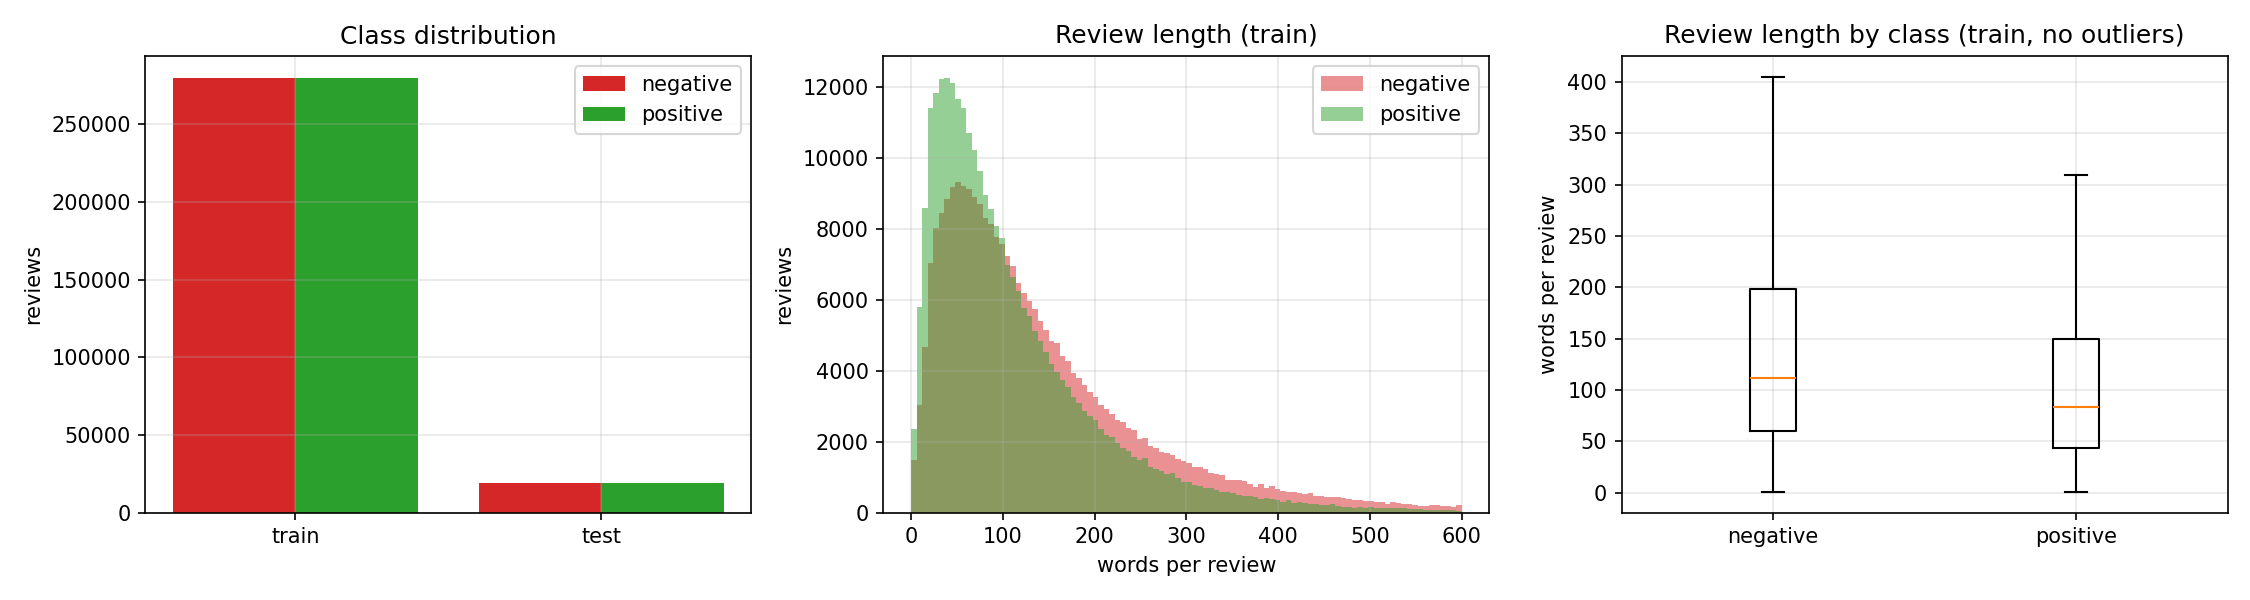

{
 "stopwords_removed": 195,
 "negations_kept": [
  "cannot",
  "neither",
  "never",
  "no",
  "nobody",
  "none",
  "nor",
  "not",
  "nothing",
  "nowhere"
 ],
 "n_train": 504000,
 "n_val": 56000,
 "n_test": 38000,
 "vocab_size": 40159,
 "tokens_per_review_mean": 68.91976607142857,
 "tokens_per_review_median": 50.0,
 "tokens_per_review_p95": 191.0,
 "truncated_share": 0.019980357142857143,
 "empty_after_preprocessing_train": 46,
 "empty_after_preprocessing_test": 0,
 "unk_rate_val": 0.005133640186234066,
 "unk_rate_test": 0.00485306519064998,
 "examples": [
  {
   "raw": "Unfortunately, the frustration of being Dr. Goldberg's patient is a repeat of the experience I've had with so many other doctors in NYC -- good doctor, terrible staff.  It seems that his staff simply never answers the phone.  It usually takes 2 hours of repeated calling to get an answer.  Who has ti",
   "tokens": [
    "unfortun",
    "frustrat",
    "dr",
    "goldberg",
    "patient",
    "repeat",
    "experi",

In [13]:
import json, pandas as pd
from IPython.display import Image, display
OUT = "task2_sentiment/kruthika/outputs"
pd.set_option("display.max_columns", 100); pd.set_option("display.width", 200)
print(json.dumps(json.load(open(f"{OUT}/eda/eda_stats.json")), indent=1))
display(Image(f"{OUT}/eda/class_and_length.png"))
print(json.dumps({k: v for k, v in json.load(open("task2_sentiment/kruthika/data_processed/preprocessing_stats.json")).items()}, indent=1))

In [14]:
cols = ["model", "accuracy", "accuracy_ci_low", "accuracy_ci_high", "f1_macro", "f1_macro_ci_low", "f1_macro_ci_high",
        "f1_micro", "f1_weighted", "precision_macro", "recall_macro", "roc_auc", "pr_auc", "mcc", "mcc_ci_low", "mcc_ci_high",
        "brier", "ece", "parameters", "train_time_s", "train_examples_per_s", "epochs_run", "best_epoch"]
comp = pd.read_csv(f"{OUT}/comparison.csv")
display(comp[[c for c in cols if c in comp]].T)
display(pd.read_csv(f"{OUT}/mcnemar.csv"))
display(pd.read_csv(f"{OUT}/slice_metrics.csv").pivot_table(index=["slice", "value"], columns="model", values=["f1_macro", "error_rate"]))

,0,1,2
model,baseline_mean_embedding,exp1_bilstm,exp2_textcnn
accuracy,0.932605,0.953105,0.943526
accuracy_ci_low,0.930079,0.950947,0.941211
accuracy_ci_high,0.935159,0.955026,0.945632
f1_macro,0.932604,0.953105,0.943525
f1_macro_ci_low,0.930077,0.950946,0.94121
f1_macro_ci_high,0.935154,0.955024,0.945632
f1_micro,0.932605,0.953105,0.943526
f1_weighted,0.932604,0.953105,0.943525
precision_macro,0.932636,0.953118,0.943554


,baseline,experimental,b_base_only_correct,c_exp_only_correct,chi2,p_value,p_value_exact
0,baseline_mean_embedding,exp1_bilstm,588,1367,309.608184,2.658149e-69,3.366031e-71
1,baseline_mean_embedding,exp2_textcnn,677,1092,96.888638,7.333834e-23,4.666639e-23


error_rate                                         f1_macro                         
model                       baseline_mean_embedding exp1_bilstm exp2_textcnn baseline_mean_embedding exp1_bilstm exp2_textcnn
slice    value                                                                                                               
contrast has contrast word                 0.075062    0.051144     0.061291                0.924095    0.948383     0.938157
         no contrast word                  0.056766    0.041005     0.049796                0.942163    0.958187     0.949203
length   long (>200)                       0.064961    0.043799     0.057059                0.930535    0.953495     0.939412
         medium (51-200)                   0.067684    0.045296     0.054553                0.932314    0.954704     0.945447
         short (<=50 words)                0.068682    0.052980     0.060350                0.928454    0.944848     0.937043
negation has negation                      0.072470    0.048089     0.057742                0.924887    0.950362     0.940387
         no negation                       0.052835    0.043469     0.052835                0.927393    0.940677     0.927223

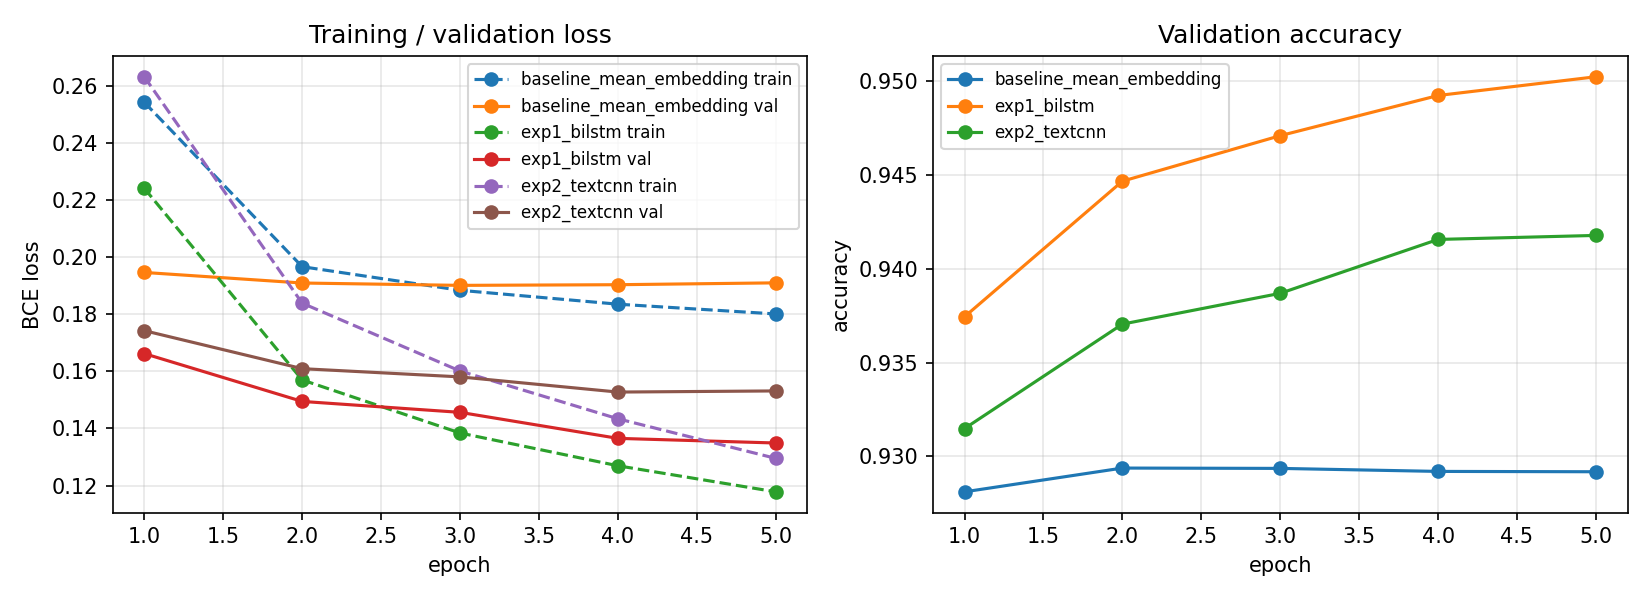

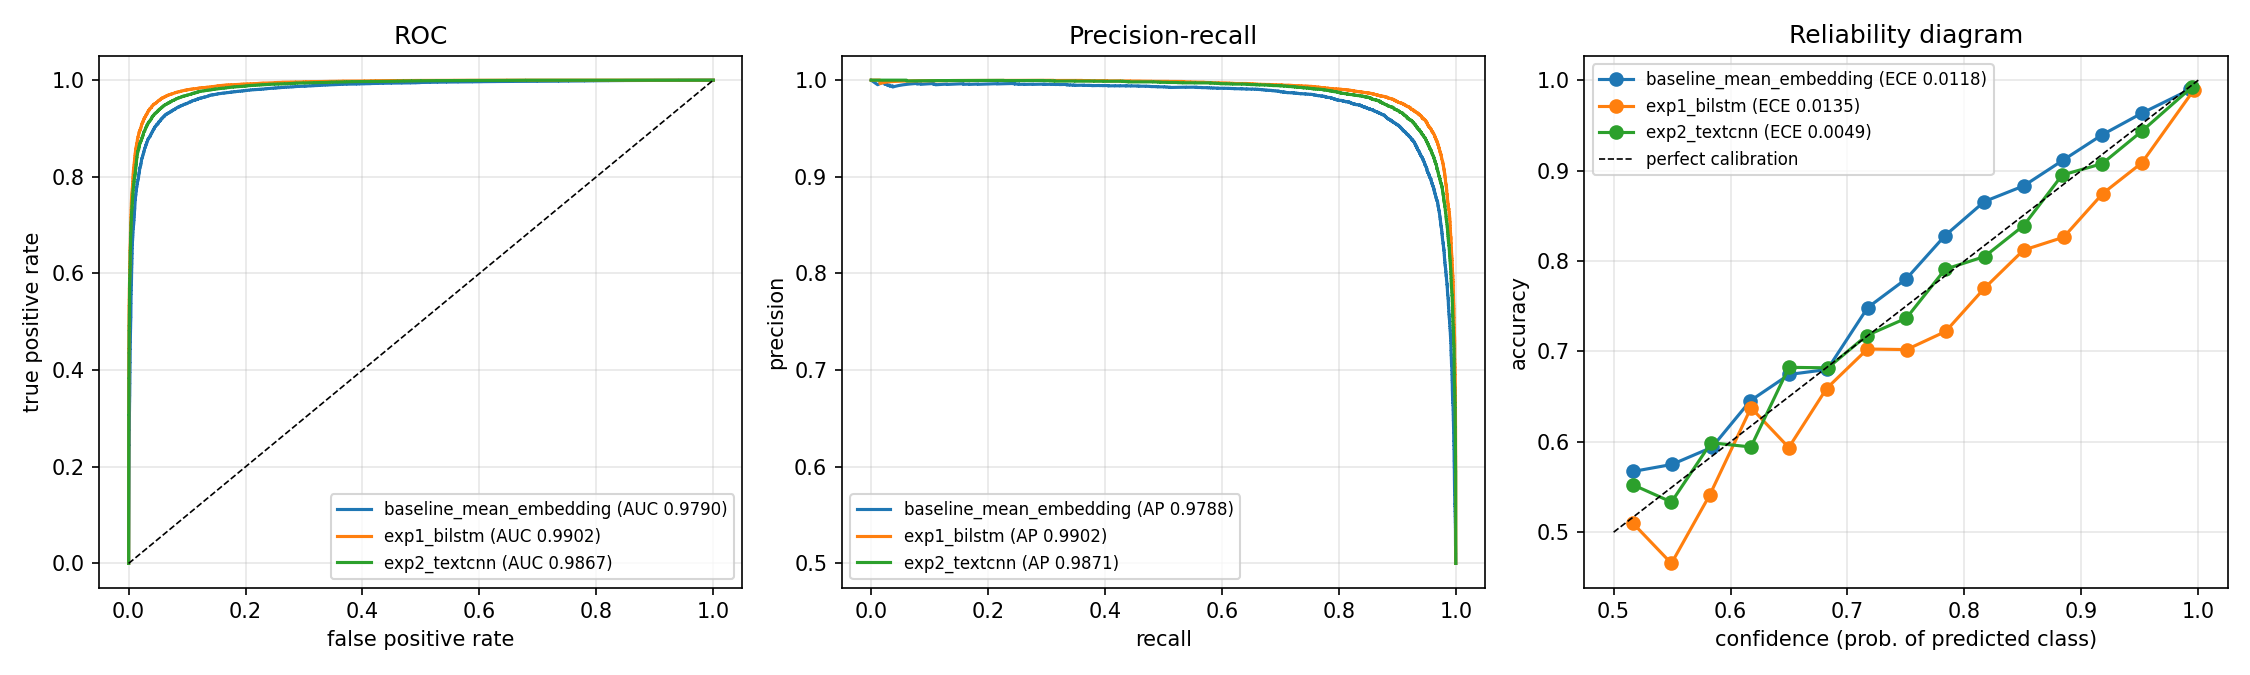

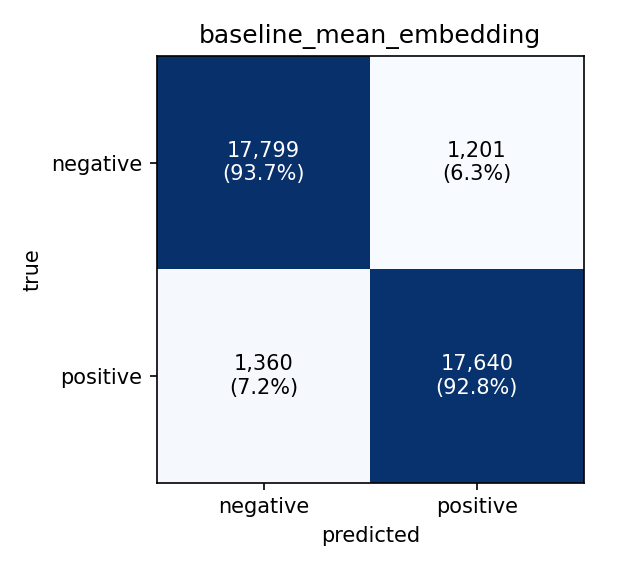

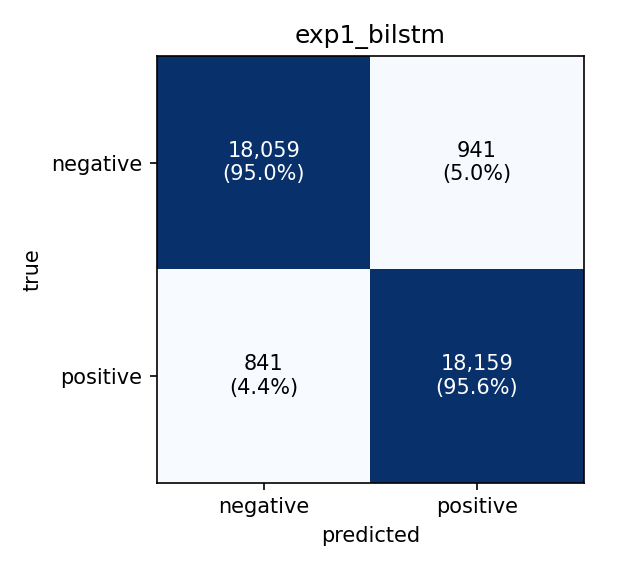

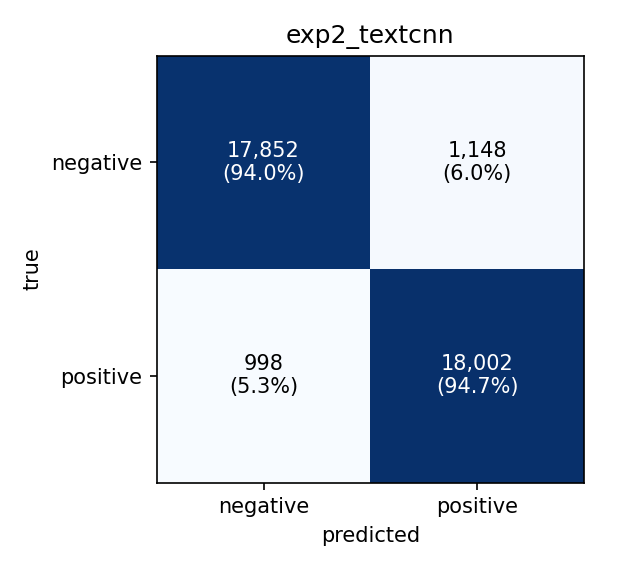

In [15]:
display(Image(f"{OUT}/training_curves.png"))
display(Image(f"{OUT}/roc_pr_calibration.png"))
for m in comp["model"]:
    display(Image(f"{OUT}/{m}/confusion_matrix.png"))

In [16]:
err = pd.read_csv(f"{OUT}/error_candidates.csv")
pd.set_option("display.max_colwidth", 300)
display(err.groupby(["model", "category"]).head(3)[["model", "category", "true", "prob_positive", "text"]])

,model,category,true,prob_positive,text
0,baseline_mean_embedding,confident_false_positive,0,1.000000e+00,What I love about Rubios' is that they always have beer. Always.\n\nThat is all I love though...
1,baseline_mean_embedding,confident_false_positive,0,9.999994e-01,Large variety
2,baseline_mean_embedding,confident_false_positive,0,9.999989e-01,Yay. Cafeteria food. Yay.
10,baseline_mean_embedding,confident_false_negative,1,3.971033e-08,The margaritas wont do ya dirty!
11,baseline_mean_embedding,confident_false_negative,1,2.242099e-06,"Its a nice buffet looking over the Aria pool, but variety was just ok.... Meh.."
12,baseline_mean_embedding,confident_false_negative,1,5.629172e-06,"Their Sago with Gulaman is pretty good! Not too sweet, not too bland, just right!"
20,baseline_mean_embedding,near_threshold,0,5.001711e-01,"While in Tempe for work, the group was told that Monti's was a good place for steaks. I think good is the right term, because it isn't 'great'. Not that any one thing made it only 'good', but that is how I felt leaving this establishment. \n\nThe waiter was very accommodating, but had a heavy ac..."
21,baseline_mean_embedding,near_threshold,1,4.998211e-01,"Port Authority (formerly known as PATransit, or \""""PAT\"""") operates a fairly extensive network of buses and (in the South Hills) light rail. Instead of running school buses, the school district gave high schoolers bus passes to get to class, and I have used the bus since 1997.\n\nI've had a grea..."
22,baseline_mean_embedding,near_threshold,0,5.003428e-01,"I'm not a big fan of Walmart, I prefer Target hands down. It seems like no matter what location I go to they always smell so weird. I have been to this location a few times since moving into the area. Prices are low but so is the quality, you get what you pay for! My last visit here was with my ..."
30,baseline_mean_embedding,slice:contrast=has contrast word,0,9.997197e-01,Looks good from far but far from good.


## 8. Download results
Zips logs, manifests, metrics, plots, predictions, vocab and the best checkpoints
(not the dataset or the cached preprocessing arrays). Unzip into the repo root: the folders line up.

In [17]:
!rm -f task2_results.zip
!zip -qr task2_results.zip reproducibility task2_sentiment/kruthika -x "*.npz" "*__pycache__*" "task2_sentiment/kruthika/src/*"
!ls -lh task2_results.zip
from google.colab import files
files.download("task2_results.zip")

-rw------- 1 root root 58M Oct  2 03:28 task2_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>